# DP1 Handling missing data by removal of data records

Imports of libraries and datasets.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/dataIsRemovalAllowed.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   1       999 non-null    int64  
 1   67      999 non-null    int64  
 2   NaN     758 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 23.5 KB


Problem; weird column names. I'll load the dataset without the header and assign my own names.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataIsRemovalAllowed.csv', header=None, names=['gender', 'age', 'preference'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   gender      1000 non-null   int64  
 1   age         1000 non-null   int64  
 2   preference  758 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 23.6 KB


In [ ]:
df.describe()

,gender,age,preference
count,1000.000000,1000.000000,758.000000
mean,0.513000,39.724000,4.530885
std,0.500081,23.207637,1.841698
min,0.000000,1.000000,0.732730
25%,0.000000,19.000000,3.060125
50%,1.000000,40.000000,4.301550
75%,1.000000,60.000000,5.892150
max,1.000000,80.000000,9.316700


In [ ]:
len(df)

1000

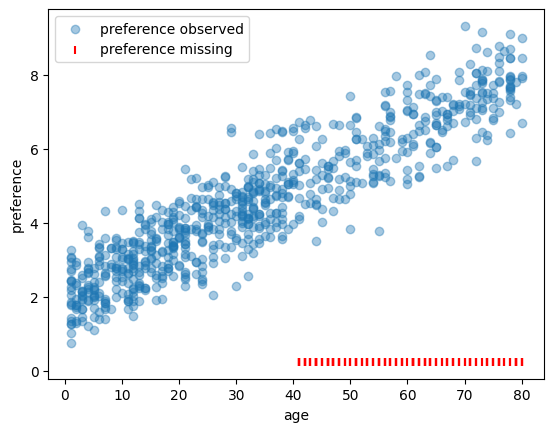

/tmp/ipykernel_981/2295361688.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.cut(df['age'], 8))['missing'].mean().plot(kind='bar')


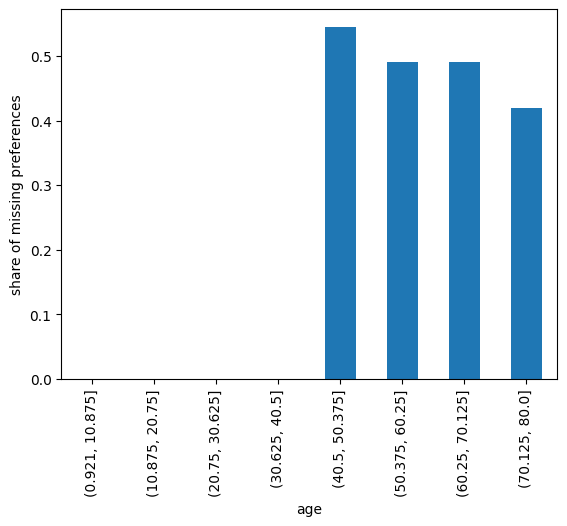

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

df['missing'] = df['preference'].isna()

# relationship between age and preference (scatter)
plt.scatter(df['age'], df['preference'], alpha=0.4, label='preference observed')
# ticks below the plot mark the age of people whose preference is missing
ymin = df['preference'].min() - 0.5
plt.scatter(df.loc[df.missing, 'age'], [ymin] * df.missing.sum(),
            marker='|', color='red', label='preference missing')
plt.xlabel('age')
plt.ylabel('preference')
plt.legend()
plt.show()

# share of missing preferences by age group
df.groupby(pd.cut(df['age'], 8))['missing'].mean().plot(kind='bar')
plt.ylabel('share of missing preferences')
plt.show()

From these graphs we can draw conclusions that preferences are missing for the older age groups. Older age groups usually have higher prefrences. If we remove the missing values, most of our samples will be young people, who have lower prefrences, thus resulting in underestimation.

In [ ]:
obs = df.dropna(subset=['preference']) # new table with nonnan prefrence
slope, intercept = np.polyfit(obs['age'], obs['preference'], 1) # basically linear regression, fit a line
df['preference_imputed'] = df['preference'].fillna(slope * df['age'] + intercept)

print('Mean after dropping rows:', obs['preference'].mean())
print('Mean with imputation:    ', df['preference_imputed'].mean())

Mean after dropping rows: 4.530885131926121
Mean with imputation:     4.9868640606034464


# DP2 Handling missing timeseries data using data imputation methods

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ex22PM10imputation.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17519 entries, 0 to 17518
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   642.2;642.2  17519 non-null  object
dtypes: object(1)
memory usage: 137.0+ KB


We face similar problem as in the previous task, so I have to reload the dataset.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ex22PM10imputation.csv', sep=';', header=None, names=['pm10_missing', 'pm10_true'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pm10_missing  17220 non-null  float64
 1   pm10_true     17520 non-null  float64
dtypes: float64(2)
memory usage: 273.9 KB


For each setting from the task I'll have one cell block. Every cell shall use evaluate(imputed, name) function.

a) Substitution with mean

mean value used: 20.86
mean       RMSE = 16.15   MAE = 11.82


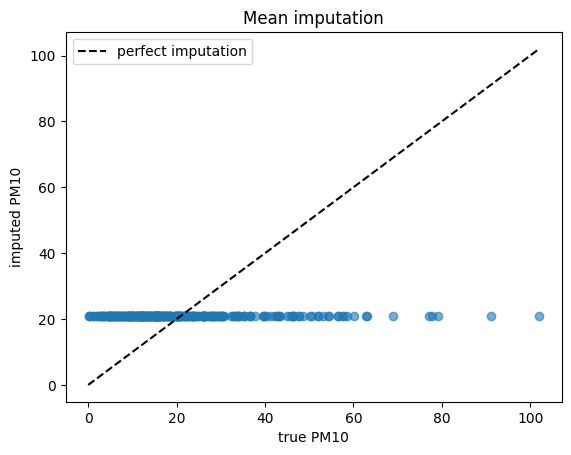

In [ ]:
mask = df['pm10_missing'].isna() # True where the value is missing

# mean imputation
mean_value = df['pm10_missing'].mean() # mean of observed values (NaN is ignored)
df['imp_mean'] = df['pm10_missing'].fillna(mean_value)

# compare imputed values with the true ones
def evaluate(imputed, name):
    error = imputed[mask] - df.loc[mask, 'pm10_true']
    rmse = np.sqrt((error ** 2).mean())
    mae = error.abs().mean()
    print(f'{name:10s} RMSE = {rmse:.2f}   MAE = {mae:.2f}')
    return rmse, mae

print('mean value used:', round(mean_value, 2))
evaluate(df['imp_mean'], 'mean')

# plot imputed vs true values at the missing positions
plt.scatter(df.loc[mask, 'pm10_true'], df.loc[mask, 'imp_mean'], alpha=0.6)
lims = [0, df.loc[mask, 'pm10_true'].max()]
plt.plot(lims, lims, 'k--', label='perfect imputation')
plt.xlabel('true PM10')
plt.ylabel('imputed PM10')
plt.title('Mean imputation')
plt.legend()
plt.show()

b) Substitution with last known value

Last known value RMSE = 3.90   MAE = 2.11


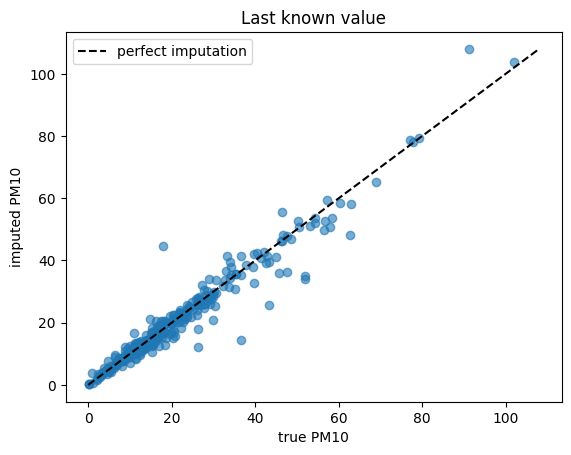

In [ ]:
# last known value
df['imp_last_val'] = df['pm10_missing'].ffill()

evaluate(df['imp_last_val'], 'Last known value')

# plot imputed vs true values at the missing positions
plt.scatter(df.loc[mask, 'pm10_true'], df.loc[mask, 'imp_last_val'], alpha=0.6)
lims = [0, max(df.loc[mask, 'pm10_true'].max(), df.loc[mask, 'imp_last_val'].max())]
plt.plot(lims, lims, 'k--', label='perfect imputation')
plt.xlabel('true PM10')
plt.ylabel('imputed PM10')
plt.title('Last known value')
plt.legend()
plt.show()

c) Linear interpolation

Linear interpolation RMSE = 2.48   MAE = 1.36


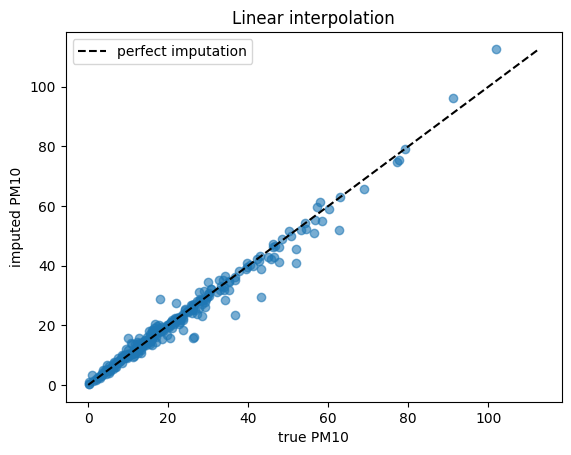

In [ ]:
# linear interpolation between the last and the next known value
df['imp_linear'] = df['pm10_missing'].interpolate(method='linear')

evaluate(df['imp_linear'], 'Linear interpolation')

# plot imputed vs true values at the missing positions
plt.scatter(df.loc[mask, 'pm10_true'], df.loc[mask, 'imp_linear'], alpha=0.6)
lims = [0, max(df.loc[mask, 'pm10_true'].max(), df.loc[mask, 'imp_linear'].max())]
plt.plot(lims, lims, 'k--', label='perfect imputation')
plt.xlabel('true PM10'); plt.ylabel('imputed PM10')
plt.title('Linear interpolation'); plt.legend(); plt.show()

d) Datetime approach

day before RMSE = 13.30   MAE = 9.85


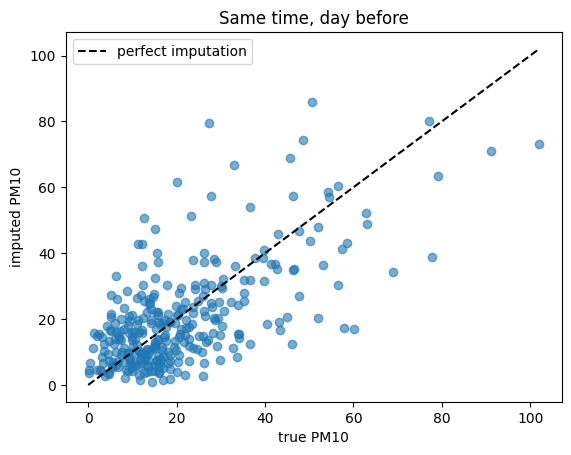

In [ ]:
day_before = df['pm10_missing'].shift(48) # shifts the series 48 rows down
df['imp_daybefore'] = df['pm10_missing'].fillna(day_before)

evaluate(df['imp_daybefore'], 'day before')

# plot imputed vs true values at the missing positions
plt.scatter(df.loc[mask, 'pm10_true'], df.loc[mask, 'imp_daybefore'], alpha=0.6)
lims = [0, max(df.loc[mask, 'pm10_true'].max(), df.loc[mask, 'imp_daybefore'].max())]
plt.plot(lims, lims, 'k--', label='perfect imputation')
plt.xlabel('true PM10')
plt.ylabel('imputed PM10')
plt.title('Same time, day before')
plt.legend()
plt.show()

# DP3 Usage of EDA for discussion of the previous data imputation results

a)

The best method for this time series is linear interpolation. The result is expected since this method uses the previous and the following value which best describes the current value.

b)

share of imputed values: 1.71 %
MAE of imputation: 1.36
mean change between consecutive values: 2.09
mean / std of the series: 20.87 / 17.24
       true series  imputed series
count    17520.000       17520.000
mean        20.868          20.864
std         17.243          17.238
min          0.100           0.100
25%          9.400           9.400
50%         16.500          16.500
75%         27.500          27.500
max        642.200         642.200


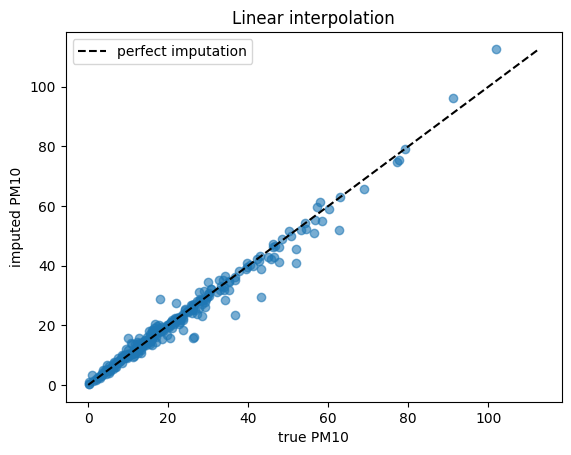

In [ ]:
best = df['imp_linear']
true = df.loc[mask, 'pm10_true']
err = best[mask] - true

print('share of imputed values:', round(mask.mean() * 100, 2), '%')
print('MAE of imputation:', round(err.abs().mean(), 2))
print('mean change between consecutive values:', round(df['pm10_true'].diff().abs().mean(), 2))
print('mean / std of the series:', round(df['pm10_true'].mean(), 2), '/', round(df['pm10_true'].std(), 2))

# Does imputation change the statistics of the whole series?
print(pd.DataFrame({'true series': df['pm10_true'].describe(),
                    'imputed series': best.describe()}).round(3))

# Scatter: imputed vs true
plt.scatter(true, best[mask], alpha=0.6)
lims = [0, max(true.max(), best[mask].max())]
plt.plot(lims, lims, 'k--', label='perfect imputation')
plt.xlabel('true PM10')
plt.ylabel('imputed PM10')
plt.title('Linear interpolation')
plt.legend()
plt.show()

The imputation error is low. The mean absolute error of linear interpolation is smaller than the typical natural change between two consecutive measurements, and it is small compared to the mean level and the standard deviation of the series. In the scatter plot, the imputed values lie close to the diagonal over the whole range of values.

c)

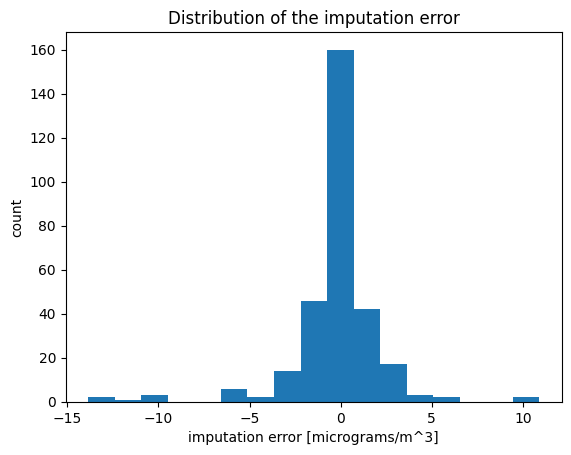

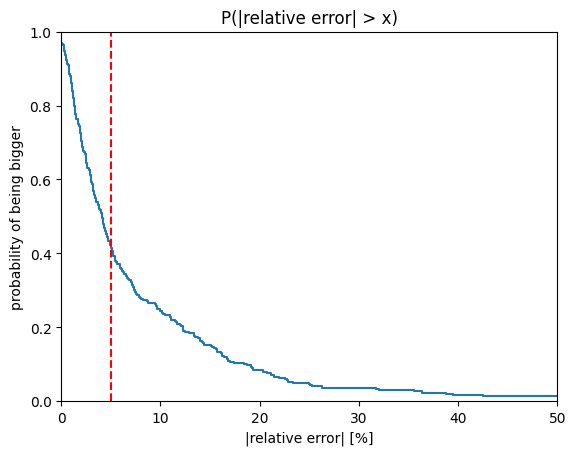

P(|relative error| > 5%) = 0.42


In [ ]:
rel = err / true * 100 # error divided by true value to see the scale of miss compared to the real value

# distribution of the error
plt.hist(err, bins=int(np.sqrt(len(err))))
plt.xlabel('imputation error [micrograms/m^3]')
plt.ylabel('count')
plt.title('Distribution of the imputation error')
plt.show()

# probability that |relative error| is bigger than x
plt.ecdf(rel.abs(), complementary=True) # we only observe absolute errors
                                        # for each point on x axis y axis represent the % of values greater than x
plt.axvline(5, color='r', ls='--')
plt.xlim(0, 50)
plt.xlabel('|relative error| [%]')
plt.ylabel('probability of being bigger')
plt.title('P(|relative error| > x)')
plt.show()

print('P(|relative error| > 5%) =', round((rel.abs() > 5).mean(), 2))

d)

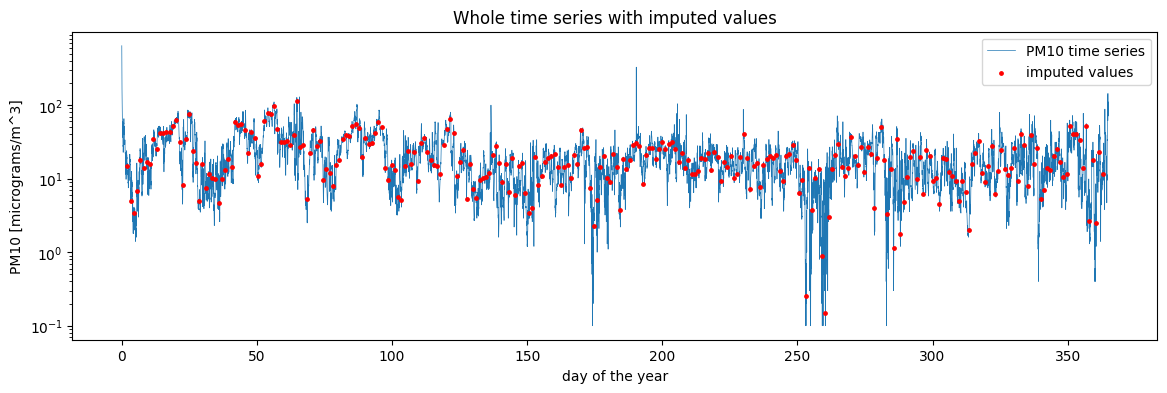

In [ ]:
days = df.index / 48 # 48 values per day -> x axis in days

plt.figure(figsize=(14, 4))
plt.plot(days, best, lw=0.5, label='PM10 time series')
plt.scatter(days[mask], best[mask], color='red', s=6, zorder=3, label='imputed values')
plt.yscale('log')
plt.xlabel('day of the year')
plt.ylabel('PM10 [micrograms/m^3]')
plt.title('Whole time series with imputed values')
plt.legend()
plt.show()

# DP4 Handling missing data by data imputation with extrapolation using regression based on other variables

a)

First, I will load a dataset from the E1 and pick features with high correlation.

   PM10Lehen  NOXLehen  RFLehen  LTLehen  O3Lehen  PM10Rud  MOXRud  RPRud  \
0      642.2      77.4     83.0      0.1      2.0    251.8    67.0   81.0   
1      336.1      47.4     81.0      0.3      2.0    244.2   133.8   78.0   
2      242.7      42.5     80.0      0.2      2.0    282.3   145.9   81.0   
3      201.1      41.1     82.0     -0.3      2.0    362.4   177.1   79.0   
4      165.7      38.2     83.0     -0.5      2.0    281.0   116.7   77.0   

   LTRud  CORud   WG     WT   GS  
0    0.7   0.60  2.7  153.0  5.0  
1    0.9   0.77  3.7  156.0  5.0  
2    0.2   0.89  2.9  166.0  4.0  
3    0.7   0.77  2.5  137.0  4.0  
4    0.6   0.62  1.8  144.0  4.0  
PM10Lehen    1.000000
PM10Rud      0.772631
CORud        0.497427
NOXLehen     0.394275
MOXRud       0.170103
WT           0.137159
RPRud        0.122158
RFLehen      0.101808
GS          -0.123114
O3Lehen     -0.199326
LTRud       -0.282703
LTLehen     -0.286483
WG          -0.291212
Name: PM10Lehen, dtype: float64


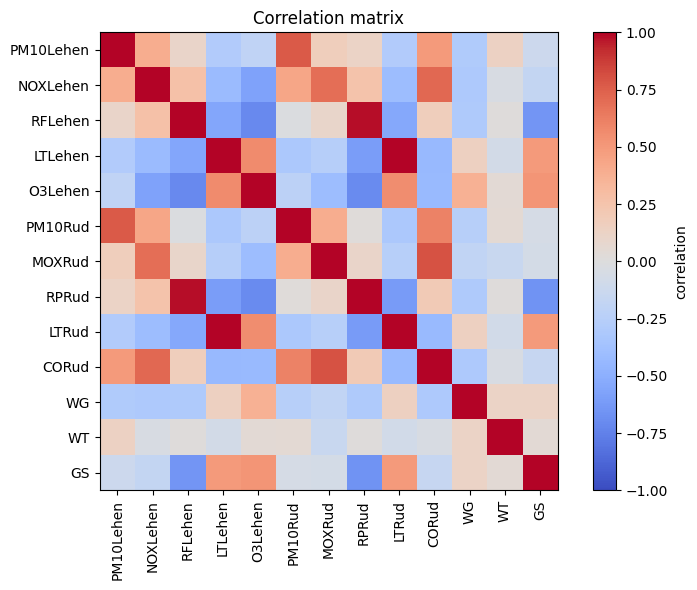

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/pollutionData.csv')
print(data.head())

# Correlation of every variable with PM10 in Lehen
corr = data.corr(numeric_only=True)
print(corr['PM10Lehen'].sort_values(ascending=False))

# Correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title('Correlation matrix')
plt.tight_layout(); plt.show()

I will pick every feature where |corr| > 0.5. Those would be PM10Rud.

In [ ]:
high_corr_feats = ['PM10Rud']
# number of NaNs in each feature (whole dataset)
print(data[high_corr_feats].isna().sum())

# number of NaNs exactly where PM10 Lehen is missing
print(data.loc[mask, high_corr_feats].isna().sum())

PM10Rud    64
dtype: int64
PM10Rud    1
dtype: int64


We can observe that there is one value missing for the PM10 Rud where there is also a missing PM10 Lehen value. We will interpolate that value in PM10 Rud.

In [ ]:
# the one position where both Lehen and PM10Rud are missing
problem = mask & data['PM10Rud'].isna()

# linearly interpolate PM10Rud and use the result only at that position
rud_interp = data['PM10Rud'].interpolate(method='linear')
data.loc[problem, 'PM10Rud'] = rud_interp[problem]

# PM10Rud should now have no NaNs where Lehen is missing
print(data.loc[mask, 'PM10Rud'].isna().sum())

0


b)

Now I can apply Linear Regression.

In [ ]:
from sklearn.linear_model import LinearRegression

X = data[['PM10Rud']] # sklearn needs a table, not a single column
y = df['pm10_missing'] # Lehen with NaNs

train = y.notna() & X['PM10Rud'].notna()
model = LinearRegression().fit(X[train], y[train])

df['imp_regression'] = y.copy()
df.loc[mask, 'imp_regression'] = model.predict(X[mask])

evaluate(df['imp_regression'], 'regression')

regression RMSE = 10.04   MAE = 7.05


(np.float64(10.043028821668115), np.float64(7.051244699816202))

c)

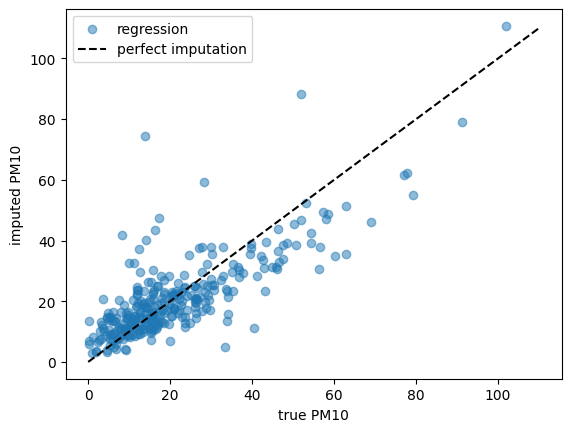

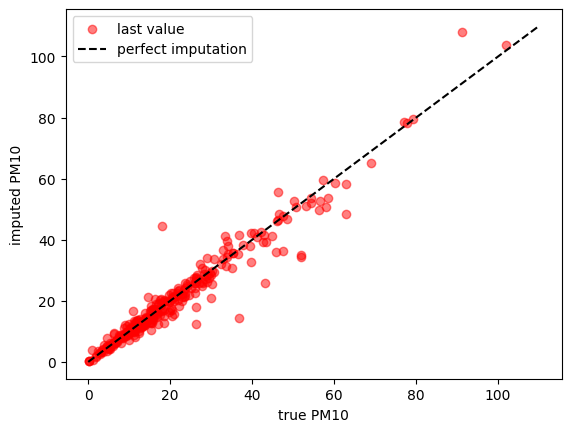

In [ ]:
true = df.loc[mask, 'pm10_true']

plt.scatter(true, df.loc[mask, 'imp_regression'], alpha=0.5, label='regression')
plt.plot([0, 110], [0, 110], 'k--', label='perfect imputation')
plt.xlabel('true PM10'); plt.ylabel('imputed PM10')
plt.legend(); plt.show()

plt.scatter(true, df.loc[mask, 'imp_last_val'], color='red', alpha=0.5, label='last value')
plt.plot([0, 110], [0, 110], 'k--', label='perfect imputation')
plt.xlabel('true PM10'); plt.ylabel('imputed PM10')
plt.legend(); plt.show()

We can observe that in this case last known value is working better. That is because time measurements are close to eachother, so this method is more accurate. Other reason might be insufficient number of features selected for linear regression.

# DP5 Feature selection based on high correlation in Python

a)

First, I will redo the first steps of the analysis exactly how it is done on the website.

Feature 0: 0.009419
Feature 1: 1.018881
Feature 2: 1.205187
Feature 3: 0.000138
Feature 4: 0.167511
Feature 5: 5.985083
Feature 6: 0.062405
Feature 7: 1.455257
Feature 8: 0.420384
Feature 9: 101.392225
Feature 10: 0.387091
Feature 11: 1.581124
Feature 12: 3.014463
Feature 13: 0.232705
Feature 14: 0.076281
Feature 15: 4.299652
Feature 16: 1.497530
Feature 17: 0.261242
Feature 18: 5.960005
Feature 19: 0.523219
Feature 20: 0.003365
Feature 21: 0.024178
Feature 22: 0.220958
Feature 23: 0.576770
Feature 24: 0.627198
Feature 25: 0.350687
Feature 26: 0.281877
Feature 27: 0.584210
Feature 28: 52.196337
Feature 29: 0.046855
Feature 30: 0.147323
Feature 31: 0.368485
Feature 32: 0.077631
Feature 33: 0.698140
Feature 34: 45.744046
Feature 35: 2.047376
Feature 36: 0.786270
Feature 37: 0.996190
Feature 38: 2.733533
Feature 39: 63.957656
Feature 40: 231.885540
Feature 41: 1.372448
Feature 42: 0.581860
Feature 43: 1.072930
Feature 44: 1.066976
Feature 45: 0.344656
Feature 46: 13.951551
Feature 47: 3.5

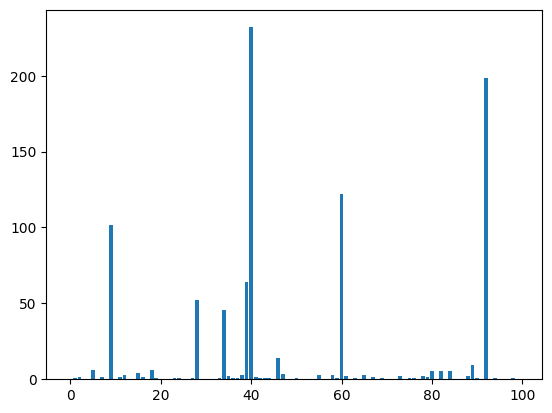

In [ ]:
# example of correlation feature selection for numerical data
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from matplotlib import pyplot

# feature selection
def select_features(X_train, y_train, X_test):
	# configure to select all features
	fs = SelectKBest(score_func=f_regression, k='all')
	# learn relationship from training data
	fs.fit(X_train, y_train)
	# transform train input data
	X_train_fs = fs.transform(X_train)
	# transform test input data
	X_test_fs = fs.transform(X_test)
	return X_train_fs, X_test_fs, fs

# load the dataset
X, y = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=0.1, random_state=1)
# split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
# feature selection
X_train_fs, X_test_fs, fs = select_features(X_train, y_train, X_test)
# what are scores for the features
for i in range(len(fs.scores_)):
	print('Feature %d: %f' % (i, fs.scores_[i]))
# plot the scores
pyplot.bar([i for i in range(len(fs.scores_))], fs.scores_)
pyplot.show()

Now I will try two models, one with all features and one with only 10 best features.

In [ ]:
from sklearn.metrics import mean_absolute_error

for k in [10, 'all']:
    fs = SelectKBest(score_func=f_regression, k=k).fit(X_train, y_train)
    model = LinearRegression().fit(fs.transform(X_train), y_train)
    yhat = model.predict(fs.transform(X_test))
    print(f'k={k}: MAE = {mean_absolute_error(y_test, yhat):.3f}')

k=10: MAE = 2.740
k=all: MAE = 0.086


For now, we can observe that the model with only 10 features is much worse than the model with all features. We know that only 10 features influence the target. f_regression computes, for each feature separately, the correlation with the target and converts it into an F-score. A large F-score means a strong linear relationship, a score close to 0 means no relationship. A high score alone does not prove that the selection is good, so it has to be checked with a model. One of the informative feature has a lower F score, and instead of the noise features is chosen instead. This happens because correlation evaluates each feature on its own and only measures linear relationships. A feature can be important for the target in combination with the other features while showing almost no correlation with the target by itself.

b)

Feature 0: 0.045484
Feature 1: 0.000000
Feature 2: 0.000000
Feature 3: 0.000000
Feature 4: 0.024816
Feature 5: 0.000000
Feature 6: 0.022659
Feature 7: 0.000000
Feature 8: 0.000000
Feature 9: 0.074320
Feature 10: 0.000000
Feature 11: 0.000000
Feature 12: 0.000000
Feature 13: 0.000000
Feature 14: 0.020390
Feature 15: 0.004307
Feature 16: 0.000000
Feature 17: 0.000000
Feature 18: 0.016566
Feature 19: 0.003688
Feature 20: 0.007579
Feature 21: 0.018640
Feature 22: 0.025206
Feature 23: 0.017967
Feature 24: 0.069173
Feature 25: 0.000000
Feature 26: 0.022232
Feature 27: 0.000000
Feature 28: 0.007849
Feature 29: 0.012849
Feature 30: 0.017402
Feature 31: 0.008083
Feature 32: 0.047321
Feature 33: 0.002829
Feature 34: 0.028968
Feature 35: 0.000000
Feature 36: 0.071652
Feature 37: 0.027969
Feature 38: 0.000000
Feature 39: 0.064796
Feature 40: 0.137695
Feature 41: 0.008732
Feature 42: 0.003983
Feature 43: 0.000000
Feature 44: 0.009387
Feature 45: 0.000000
Feature 46: 0.038385
Feature 47: 0.000000
Fe

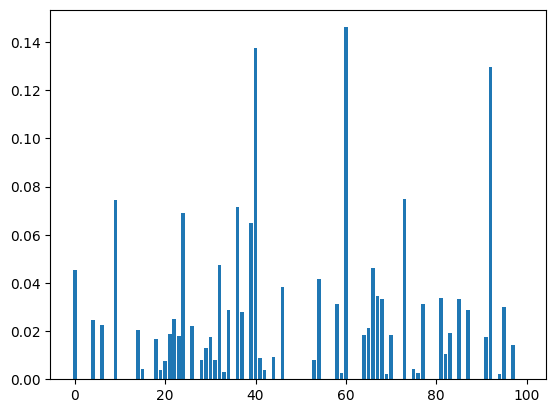

In [ ]:
from sklearn.feature_selection import mutual_info_regression

# feature selection
def select_features(X_train, y_train, X_test):
	# configure to select all features
	fs = SelectKBest(score_func=mutual_info_regression, k='all')
	# learn relationship from training data
	fs.fit(X_train, y_train)
	# transform train input data
	X_train_fs = fs.transform(X_train)
	# transform test input data
	X_test_fs = fs.transform(X_test)
	return X_train_fs, X_test_fs, fs

# load the dataset
X, y = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=0.1, random_state=1)
# split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
# feature selection
X_train_fs, X_test_fs, fs = select_features(X_train, y_train, X_test)
# what are scores for the features
for i in range(len(fs.scores_)):
	print('Feature %d: %f' % (i, fs.scores_[i]))
# plot the scores
pyplot.bar([i for i in range(len(fs.scores_))], fs.scores_)
pyplot.show()

In [ ]:
for k in [10, 88, 'all']:
    fs = SelectKBest(score_func=mutual_info_regression, k=k).fit(X_train, y_train)
    model = LinearRegression().fit(fs.transform(X_train), y_train)
    yhat = model.predict(fs.transform(X_test))
    print(f'k={k}: MAE = {mean_absolute_error(y_test, yhat):.3f}')

k=10: MAE = 68.210
k=88: MAE = 0.084
k=all: MAE = 0.086


The target in this dataset is a purely linear combination of the informative features, which is exactly the type of relationship that correlation measures. The advantage of mutual information, detecting non-linear dependencies, is therefore not needed and performs even worse on this dataset because of the lower number of samples.

The goal of feature selection is to keep only the input variables that are relevant for predicting the target and remove the irrelevant or redundant ones. This results in a simpler model that is faster to train, easier to interpret and less prone to overfitting, since it does not learn from noise.

c)

correlation [68.228, 2.74, 2.805, 2.842, 2.888, 2.911, 2.932, 0.082, 0.085, 0.085]
mutual information [78.287, 68.21, 62.052, 44.962, 44.999, 17.031, 17.208, 0.083, 0.083, 0.084]


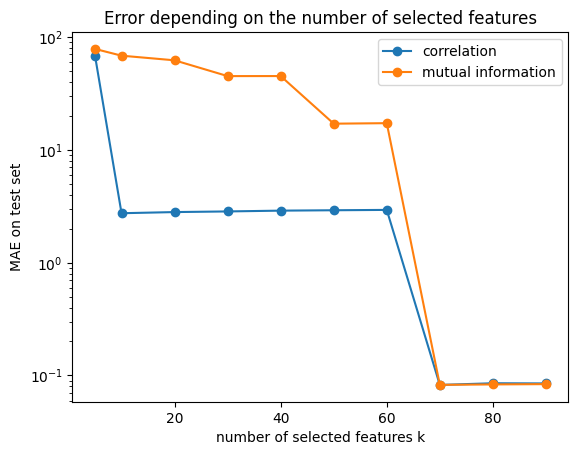

In [ ]:
ks = [5, 10, 20, 30, 40, 50, 60, 70, 80, 90]
methods = {'correlation': f_regression, 'mutual information': mutual_info_regression}
results = {}

for name, score_func in methods.items():
    maes = []
    for k in ks:
        fs = SelectKBest(score_func=score_func, k=k).fit(X_train, y_train)
        model = LinearRegression().fit(fs.transform(X_train), y_train)
        y_pred = model.predict(fs.transform(X_test))
        maes.append(mean_absolute_error(y_test, y_pred))
    results[name] = maes
    print(name, [round(m, 3) for m in maes])

for name, maes in results.items():
    plt.plot(ks, maes, marker='o', label=name)
plt.yscale('log')
plt.xlabel('number of selected features k')
plt.ylabel('MAE on test set')
plt.title('Error depending on the number of selected features')
plt.legend(); plt.show()

Here we are looking for the elbow as an optimal number of k. For correlation we have two elbows, around 10 and 60. For mutual information we have only one around 60. The elbow is the point on the error curve where the error stops decreasing noticeably. Before it, every additional feature still brings useful information, so the error drops. After it, the curve becomes flat, additional features bring no improvement and only add complexity.

For reasons stated before, correlation method is better here because we generated a linear dataset, while mutual information is better for nonlinear datasets.

# DP6 Feature generation to make linear regression models more powerful

a)

First, I need to load the dataset.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataFeatureGenerationForLinReg.csv', sep=r'\s+', header=None, names=['x1', 'x2', 'y'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      200 non-null    float64
 1   x2      200 non-null    float64
 2   y       200 non-null    float64
dtypes: float64(3)
memory usage: 4.8 KB


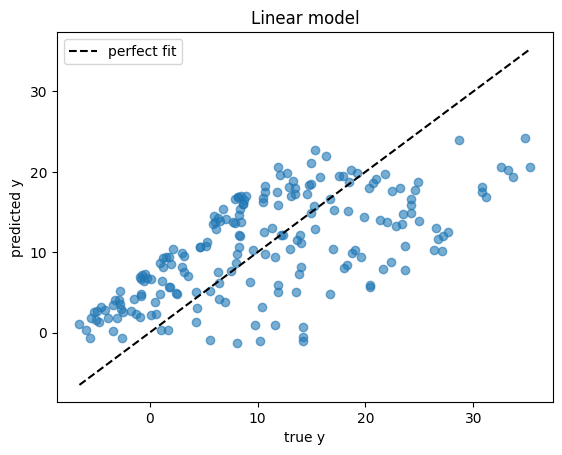

In [ ]:
X = df[['x1', 'x2']]
y = df['y']

model = LinearRegression().fit(X, y)
y_pred = model.predict(X)

plt.scatter(y, y_pred, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', label='perfect fit')
plt.xlabel('true y'); plt.ylabel('predicted y')
plt.title('Linear model')
plt.legend(); plt.show()

The model is making mistakes while predicting, as can be observed by the graph.

b)

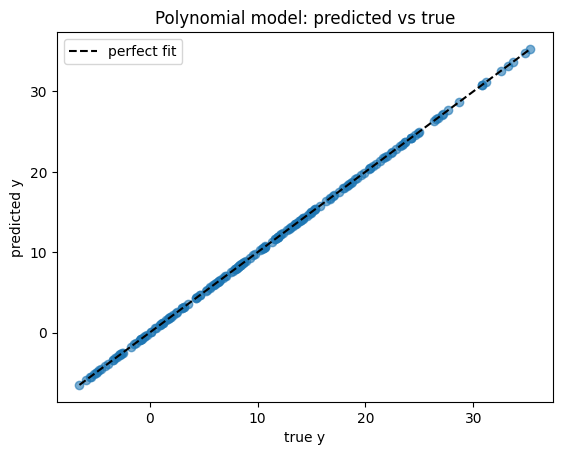

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

X_poly = PolynomialFeatures(degree=2).fit_transform(X)
model_poly = LinearRegression().fit(X_poly, y)
y_pred_poly = model_poly.predict(X_poly)

plt.scatter(y, y_pred_poly, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', label='perfect fit')
plt.xlabel('true y'); plt.ylabel('predicted y')
plt.title('Polynomial model: predicted vs true')
plt.legend(); plt.show()

The second model is way better than the first one, because y depends on one of the features quadratically, which can't be modeled with a simple linear model.

**Declaration of AI use**

**AI system**: Claude (Anthropic), model Claude Opus 5.5, used via the Claude app (claude.ai), October 2026.

**Type and extent of use**: The AI was used as a tutor and assistant throughout the exercise:

**Understanding concepts**: explanations of missing data, imputation methods, error measures, feature selection and feature generation, and how the used Python functions work.

**Code**: suggested code for tasks, which I ran in Google Colab and adapted.

**Debugging**: solving data loading problems and other errors.

**Text**: suggested wording for most explanations and conclusions, which I checked against my own results and adapted.

**Review**: checked my results and notebook and pointed out missing answers.